# Failure-aware workflow placement under estimated failure rates — v5 notebook

Successor of *AR-HEFT v4*. AR-HEFT was retired after the Stage 1 audit (`docs/STAGE1_AUDIT.md`).
This notebook is a thin, executable front end to the `fawsim` package: it runs the test suite,
demonstrates one paired replicate, and reproduces every table and figure in the manuscript
from the saved raw results. The full experiments are run by `scripts/run_experiments.py`
(about 10 minutes on 2 cores); they are not re-run here.

**Research question.** When per-VM failure rates must be estimated from monitoring, how much of the
makespan benefit of failure-aware placement (with known rates) can an online scheduler recover, and
in which regimes is failure-aware placement worth using at all?

In [1]:
import os, sys, subprocess, json
ROOT = os.path.abspath('.')
sys.path.insert(0, ROOT)
import numpy as np, pandas as pd
import fawsim
print('fawsim', fawsim.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)

fawsim 5.1.0 | numpy 2.5.3 | pandas 3.0.5


## 1. Validation tests (must pass)
Analytical (closed-form vs Monte Carlo), invariant, information-access and regression tests.

In [2]:
r = subprocess.run([sys.executable, '-m', 'unittest', 'tests.test_fawsim'], capture_output=True, text=True, cwd=ROOT)
print(r.stderr.strip().splitlines()[-3:])
assert r.returncode == 0, r.stderr

['Ran 31 tests in 28.118s', '', 'OK']


## 2. One paired replicate
All policies see the same workflow and the same outage trace; only the placement score and the information differ. A single replicate is very noisy (here known-rate ECT is 30% *worse* than EFT, although it is 6% better on average in this cell): placement changes alter which tasks the outages hit. Conclusions below rest on 1,400 paired replicates per cell.

In [3]:
from fawsim.environment import EnvConfig
from fawsim.experiments import run_replicate, INSTANCES
pols = ['EFT', 'ECT-Oracle', 'ECT-Online', 'RT-Oracle-b0.5', 'RT-Online-b0.5', 'AR-v4']
rows = run_replicate(INSTANCES[11], EnvConfig(rho=0.1, coupling='fast-volatile'), 1000, pols)
demo = pd.DataFrame(rows)[['policy', 'makespan', 'lost_work', 'interruptions', 'n_outage_intervals_run', 'run_volatile']]
demo['vs_EFT_%'] = (demo.makespan / demo.makespan.iloc[0] - 1) * 100
print(demo.round(3).to_string(index=False))

        policy  makespan  lost_work  interruptions  n_outage_intervals_run run_volatile  vs_EFT_%
           EFT    46.796     13.484             14                     771          3 7     0.000
    ECT-Oracle    60.844     28.539             18                     771          3 7    30.021
    ECT-Online    50.341     13.222             15                     771          3 7     7.577
RT-Oracle-b0.5    46.796     13.313             14                     771          3 7     0.000
RT-Online-b0.5    76.028     50.805             19                     771          3 7    62.469
         AR-v4    80.871     46.818             18                     771          3 7    72.818


## 3. Main experiment (E1): geometric-mean makespan vs EFT
100 test seeds × 14 WfCommons instances per cell; 95% stratified-bootstrap CIs.

In [4]:
subprocess.run([sys.executable, 'scripts/analyze.py'], check=True, cwd=ROOT)
res = pd.read_csv('results/analysis/E1_gm_ratio_vs_EFT.csv')
res['pct'] = (res.gm_ratio - 1) * 100
tab = res.pivot_table(index=['cfg_rho', 'cfg_coupling'], columns='policy', values='pct')
print(tab[['ECT-Oracle', 'ECT-Online', 'RT-Oracle-b0.5', 'RT-Online-b0.5', 'ECT-OraclePooled', 'AR-v4']].round(2).to_string())

policy                   ECT-Oracle  ECT-Online  RT-Oracle-b0.5  RT-Online-b0.5  ECT-OraclePooled  AR-v4
cfg_rho cfg_coupling                                                                                    
0.01    fast-volatile         -1.02       -0.13           -0.65           -0.11              0.06   0.64
        random-volatile       -0.15        0.07           -0.01            0.09              0.07   0.55
        slow-volatile          0.01        0.04            0.13            0.09              0.04   0.65
        uniform                0.10        0.11            0.09            0.09              0.10   1.28
0.03    fast-volatile         -3.29       -2.19           -3.27           -1.81              0.06   0.16
        random-volatile       -0.88       -0.42           -0.86           -0.23             -0.14   1.80
        slow-volatile          0.03        0.18            0.02           -0.01              0.08   1.77
        uniform                0.00       -0.08        

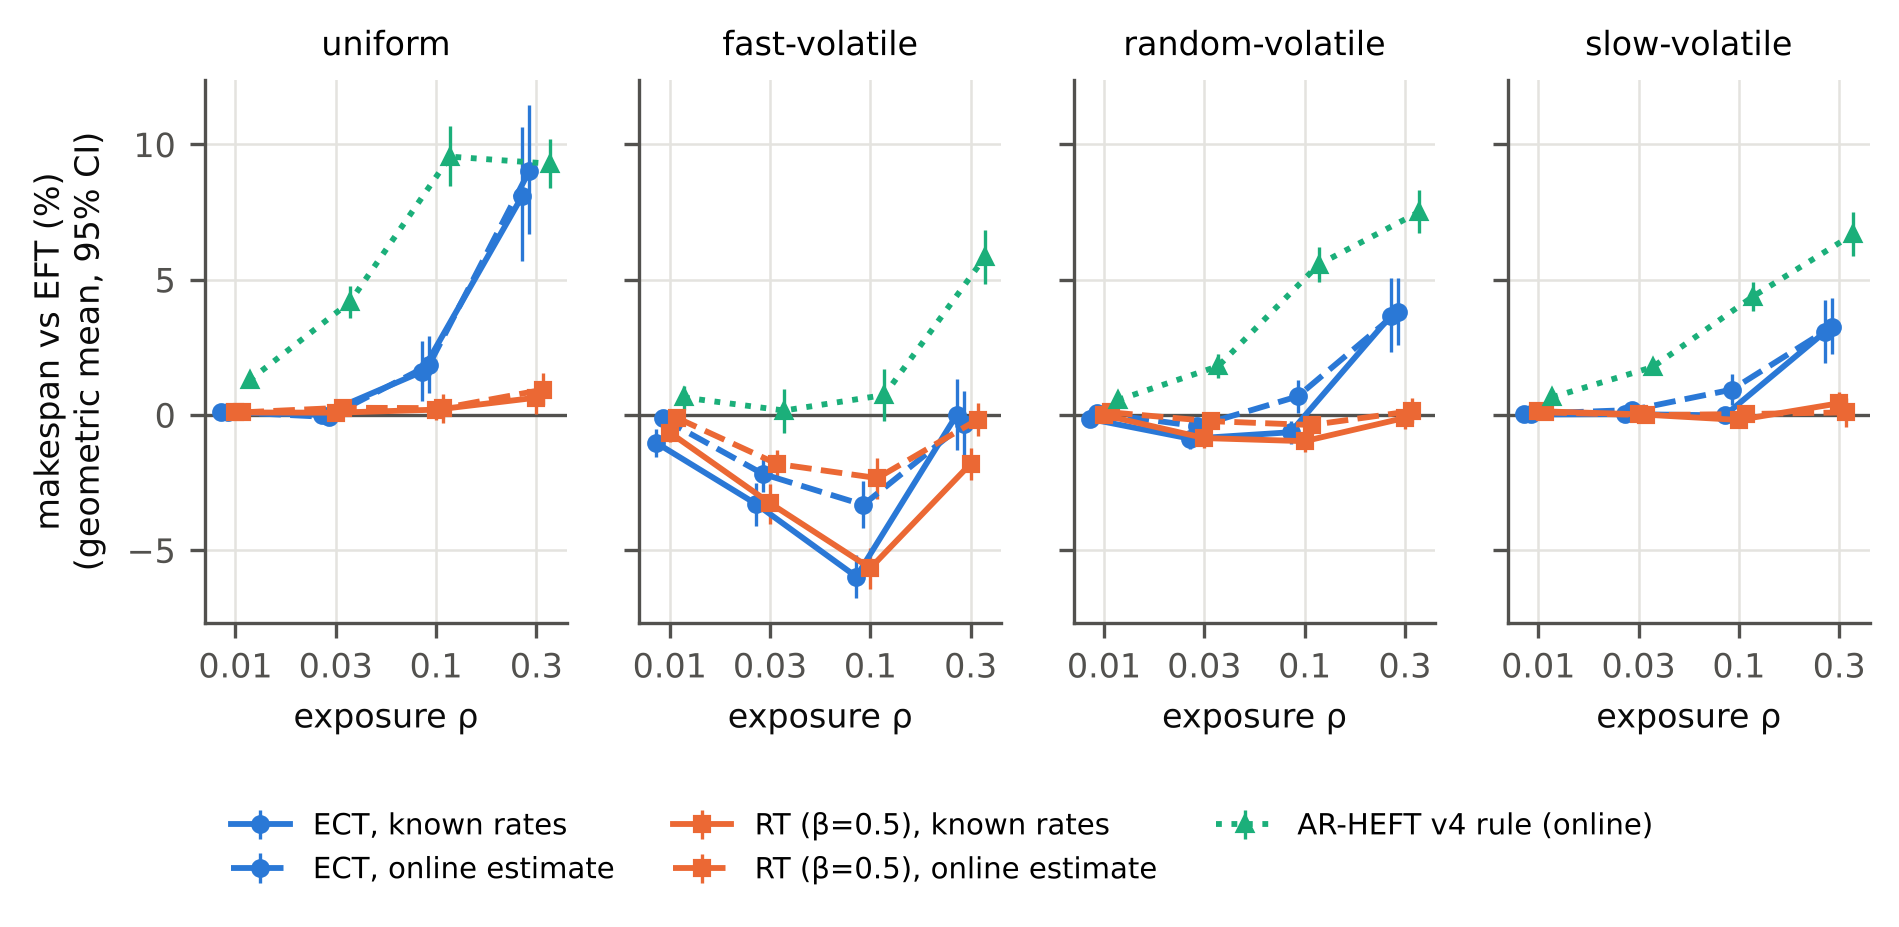

In [5]:
FIGS = ['figures/fig_main_gm_ratio.png']

## 4. Recovery of the known-rate gain by online estimation

In [6]:
rec = pd.read_csv('results/analysis/E1_recovery.csv')
print(rec[rec.oracle_gain_significant][['cfg_rho', 'cfg_coupling', 'online', 'oracle_gain', 'online_gain', 'recovery', 'rec_ci_lo', 'rec_ci_hi']].round(3).to_string(index=False))

 cfg_rho    cfg_coupling               online  oracle_gain  online_gain  recovery  rec_ci_lo  rec_ci_hi
    0.01   fast-volatile           ECT-Online        0.010        0.001     0.131     -0.101      0.351
    0.01   fast-volatile       RT-Online-b0.5        0.007        0.001     0.169     -0.066      0.398
    0.01   fast-volatile     ECT-OnlinePooled        0.010       -0.001    -0.055     -0.169      0.020
    0.01   fast-volatile RT-OnlinePooled-b0.5        0.007       -0.000    -0.033     -0.247      0.138
    0.03   fast-volatile           ECT-Online        0.033        0.022     0.664      0.541      0.786
    0.03   fast-volatile       RT-Online-b0.5        0.033        0.018     0.556      0.444      0.671
    0.03   fast-volatile     ECT-OnlinePooled        0.033       -0.000    -0.010     -0.072      0.049
    0.03   fast-volatile RT-OnlinePooled-b0.5        0.033        0.000     0.004     -0.040      0.048
    0.03 random-volatile           ECT-Online        0.009      

## 5. Monitoring history and non-stationarity (E2)

policy                                  ECT-Hist  ECT-HistDisc  ECT-Online  ECT-Oracle  RT-Hist-b0.5  RT-HistDisc-b0.5  RT-Online-b0.5  RT-Oracle-b0.5
cfg_history_k cfg_regime_shift cfg_rho                                                                                                                
5             False            0.1         -0.32         -0.01        0.45       -0.96         -0.72             -0.36           -0.24           -0.99
                               0.3          3.56          3.05        2.86        3.08          0.24              0.36            0.60           -0.04
              True             0.1          1.36          1.82        0.79       -0.67          0.87              0.40           -0.13           -0.87
                               0.3          3.59          2.73        2.02        3.02          0.82              0.42            0.25           -0.10
50            False            0.1         -0.81         -0.41        0.55       -0.61        

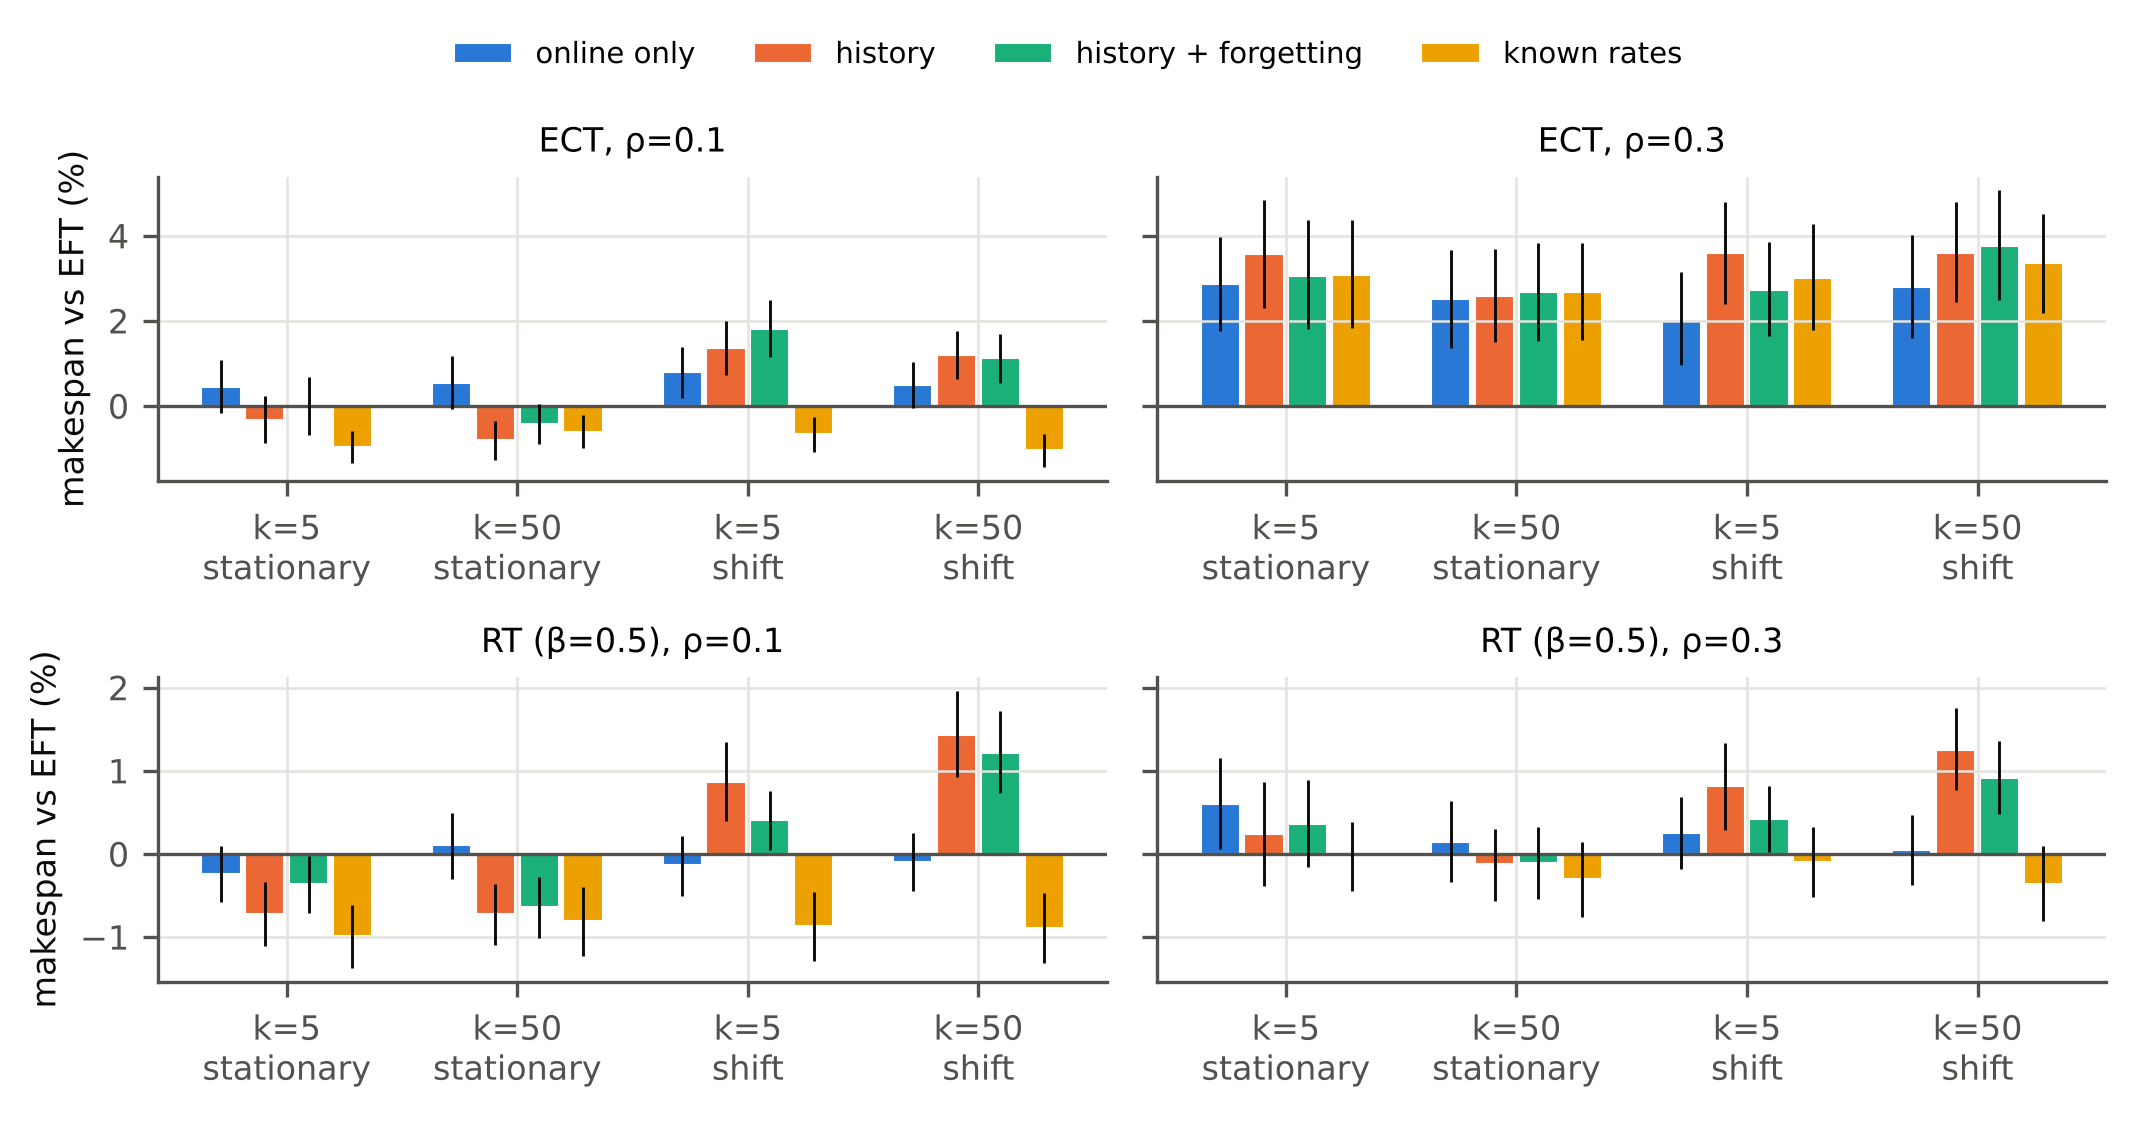

In [7]:
h = pd.read_csv('results/analysis/E2_gm_ratio_vs_EFT.csv'); h['pct'] = (h.gm_ratio - 1) * 100
print(h.pivot_table(index=['cfg_history_k', 'cfg_regime_shift', 'cfg_rho'], columns='policy', values='pct').round(2).to_string())
FIGS = ['figures/fig_history.png']

## 6. Sensitivity (E3) and correlated shock (E4)

In [8]:
s = pd.read_csv('results/analysis/E3_sensitivity.csv'); s['pct'] = (s.gm_ratio - 1) * 100
print(s.pivot_table(index='variant', columns='policy', values='pct').round(2).to_string())
k = pd.read_csv('results/analysis/E4_shock.csv'); k['pct'] = (k.gm_ratio - 1) * 100
print(k.pivot_table(index='cfg_rho', columns='policy', values='pct').round(2).to_string())

policy      ECT-Online  ECT-Online-prior0.25  ECT-Online-prior4  ECT-Oracle  RT-Online-b0.5  RT-Online-b0.5-prior0.25  RT-Online-b0.5-prior4  RT-Oracle-b0.5
variant                                                                                                                                                     
baseline         -3.56                 -3.95              -3.08       -5.75           -2.55                     -2.44                  -1.90           -5.58
m16             -20.17                -17.28             -20.54      -25.32          -14.27                    -14.66                 -13.83          -23.87
repair0.25       -9.94                -10.28              -9.24      -12.81           -8.24                     -8.73                  -7.44          -11.87
repair4          -0.61                 -1.26              -0.29       -3.10           -0.78                     -0.68                  -0.54           -2.56
volmult3         -2.65                 -4.00              

## 7. Tail behaviour and overhead

              policy  us_per_decision_mean  decisions_mean  lost_work_mean  interruptions_mean
               AR-v4                  8.52          168.38           17.44               10.57
          ECT-Online                  9.67          170.80           22.26               12.42
    ECT-OnlinePooled                  9.52          170.58           22.02               12.32
          ECT-Oracle                  7.44          171.04           21.82               12.34
    ECT-OraclePooled                  7.74          170.68           22.10               12.34
         ECTR-Online                  5.88          169.02           18.46               10.84
         ECTR-Oracle                  3.69          169.77           16.84               10.22
                 EFT                  1.80          169.57           18.69               11.38
      RT-Online-b0.5                  5.78          169.57           18.28               11.20
RT-OnlinePooled-b0.5                  5.67        

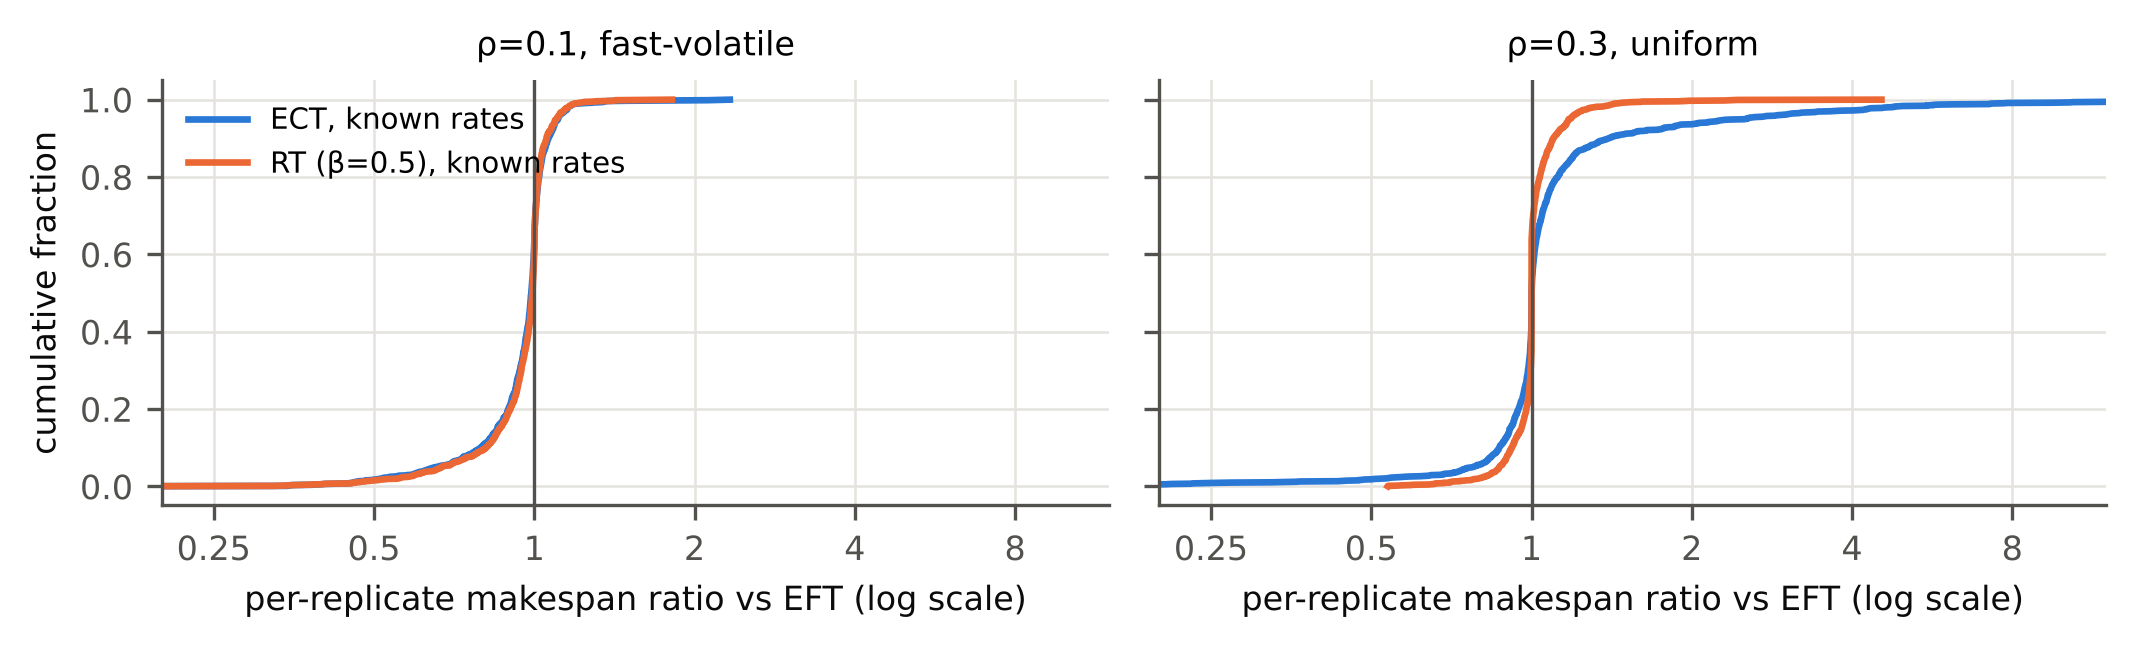

In [9]:
ov = pd.read_csv('results/analysis/E1_overhead_and_loss.csv')
print(ov.round(2).to_string(index=False))
FIGS = ['figures/fig_ecdf.png']

## 8. v5.1 — change-aware history (E5) and bursty failures (E6)
New method: a per-VM likelihood-ratio test discards stale failure history. Held-out test seeds.

E5 regret (percentage points):
                      max_regret  mean_regret  cells_best  n_cells
policy                                                            
RT-Online-b0.5              2.35         0.55           8       24
RT-Hist-b0.5                3.73         0.81           9       24
RT-HistDisc-b0.5            3.16         0.77           1       24
RT-HistCD-b0.5-a0.05        0.73         0.19           6       24

E6 regret incl. Weibull failures:
                       max_regret  mean_regret  cells_best  n_cells  max_regret_k1.0  max_regret_k0.7  max_regret_k0.5
policy                                                                                                                
RT-Online-b0.5               2.92         0.44          19       48             2.35             2.92             0.90
RT-Hist-b0.5                 3.73         0.67          13       48             3.73             3.46             1.36
RT-HistDisc-b0.5             3.16         0.58          

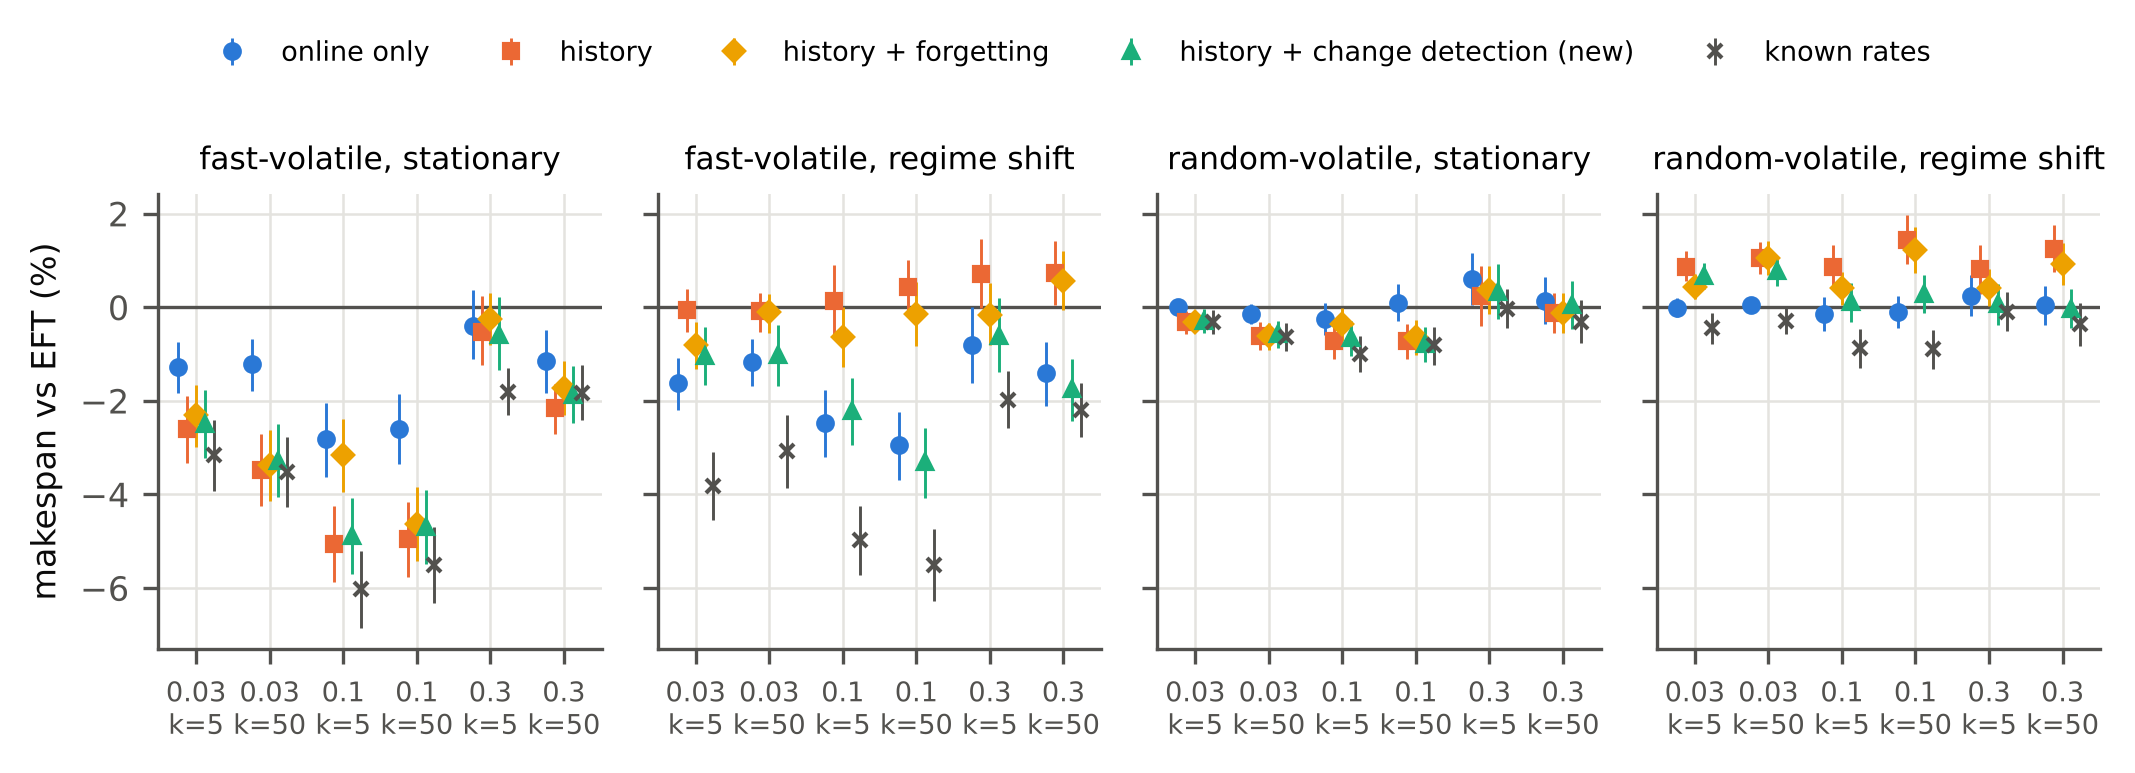

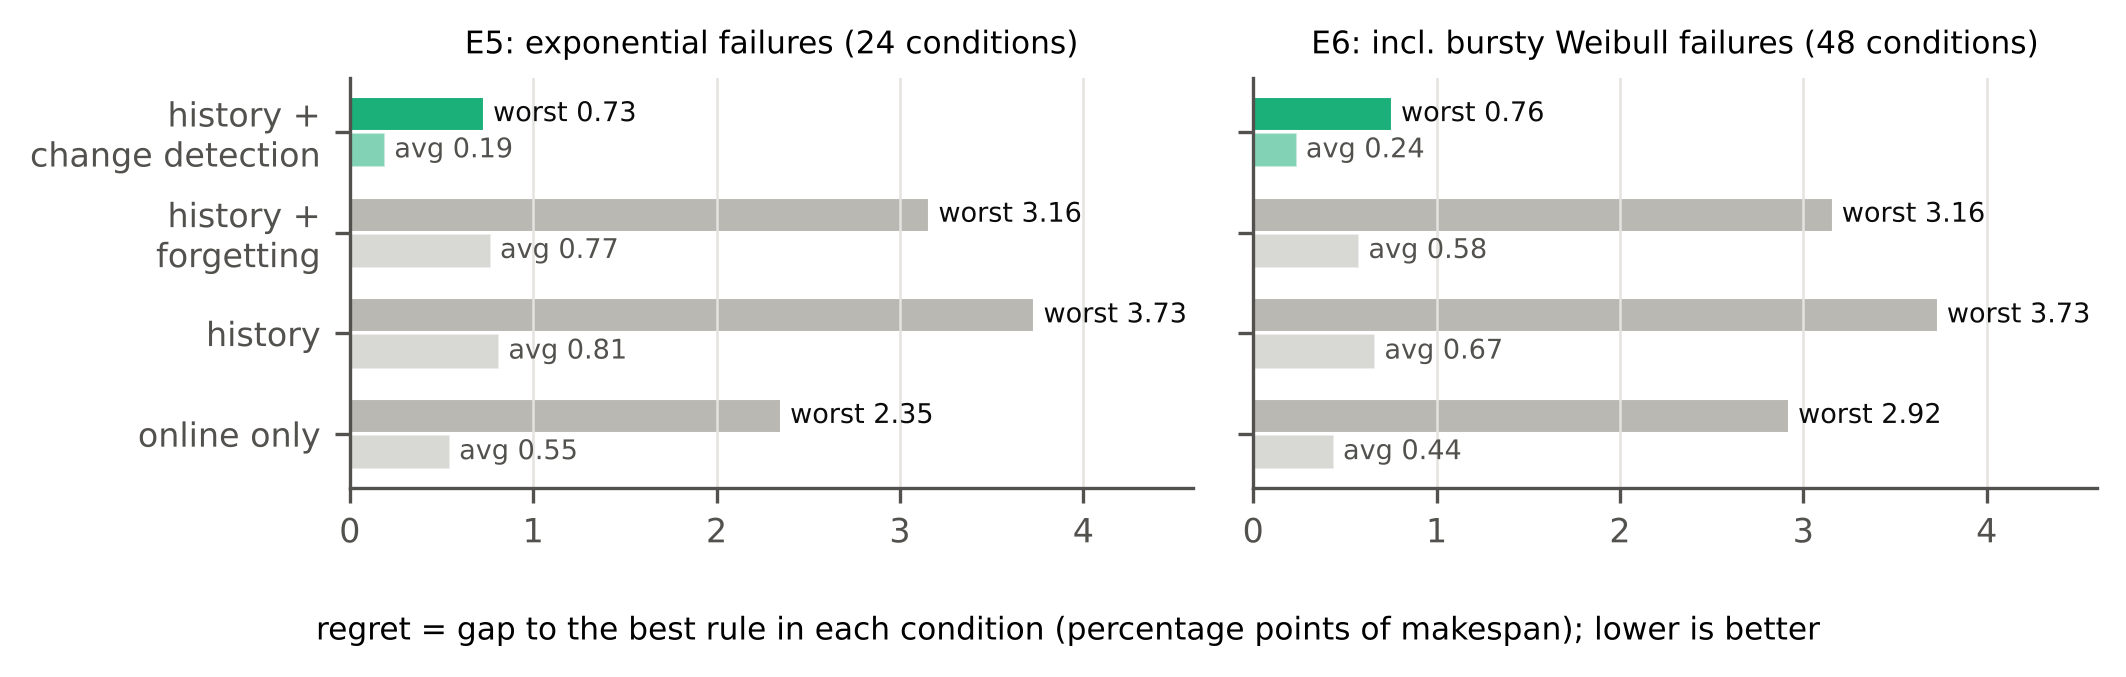

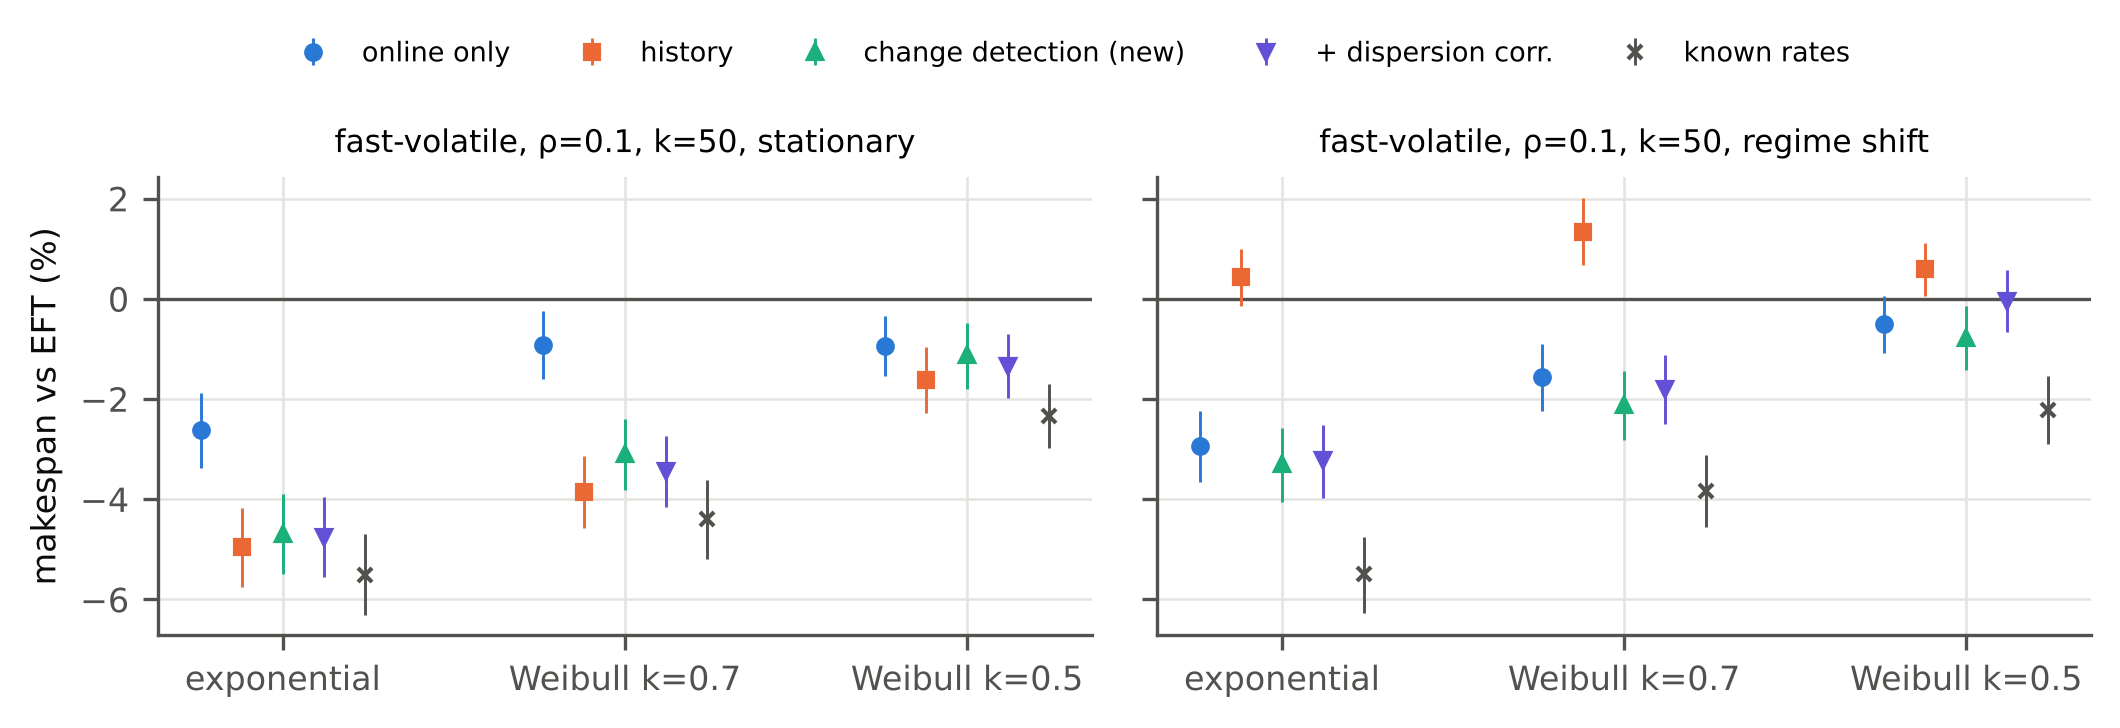

In [10]:
subprocess.run([sys.executable, 'scripts/make_tables_v51.py'], check=True, cwd=ROOT)
subprocess.run([sys.executable, 'scripts/analyze_v51.py'], check=True, cwd=ROOT)
reg = pd.read_csv('results/analysis/E5_regret.csv', index_col=0)
print('E5 regret (percentage points):'); print(reg.round(2).to_string())
r6 = pd.read_csv('results/analysis/E6_regret.csv', index_col=0)
print('\nE6 regret incl. Weibull failures:'); print(r6.round(2).to_string())
FIGS = ['figures/fig_e5_change_detection.png', 'figures/fig_regret.png', 'figures/fig_e6_bursty.png']

## 9. Limitations
Exponential up-times, fixed repair, restart-from-scratch (no checkpointing), no communication
costs, no replication, one workflow at a time, 8 heterogeneous VMs, synthetic failure
processes on real workflow structures (no real failure traces). See the manuscript's
Threats to Validity section.